# MiniGPT from scratch


In [1]:
REPO_URL = "https://github.com/layyana-junaid/AI_Engineering_Fall26.git"
import os
if not os.path.exists("transformer-gpt-assignment"):
    !git clone $REPO_URL transformer-gpt-assignment
%cd transformer-gpt-assignment
!pip install -q pyyaml matplotlib pytest fastapi uvicorn httpx
import torch; print("torch", torch.__version__, "| GPU:", torch.cuda.is_available() and torch.cuda.get_device_name(0))

c:\Users\hp\Desktop\7th Sem\AI_Engineering\transformer-gpt-assignment\notebooks\transformer-gpt-assignment


Cloning into 'transformer-gpt-assignment'...
Updating files:  12% (14/113)
Updating files:  13% (15/113)
Updating files:  14% (16/113)
Updating files:  15% (17/113)
Updating files:  16% (19/113)
Updating files:  17% (20/113)
Updating files:  18% (21/113)
Updating files:  19% (22/113)
Updating files:  20% (23/113)
Updating files:  21% (24/113)
Updating files:  22% (25/113)
Updating files:  23% (26/113)
Updating files:  24% (28/113)
Updating files:  25% (29/113)
Updating files:  26% (30/113)
Updating files:  27% (31/113)
Updating files:  28% (32/113)
Updating files:  29% (33/113)
Updating files:  30% (34/113)
Updating files:  31% (36/113)
Updating files:  32% (37/113)
Updating files:  33% (38/113)
Updating files:  34% (39/113)
Updating files:  35% (40/113)
Updating files:  36% (41/113)
Updating files:  37% (42/113)
Updating files:  38% (43/113)
Updating files:  39% (45/113)
Updating files:  40% (46/113)
Updating files:  41% (47/113)
Updating files:  42% (48/113)
Updating files:  43% (49/

torch 2.11.0+cpu | GPU: False


## 1. Data + unit tests

In [2]:
!python -m src.dataset --download
!python -m pytest -q

data/input.txt: 1,115,394 characters, 40,000 lines
....................................                                     [100%]
36 passed in 99.83s (0:01:39)


## 2. Evidence figures (hand calculation, mask, shapes, positional encoding, summary)

In [3]:
!python -m experiments.hand_calculation
!python -m experiments.make_evidence

HAND CALCULATION: scaled dot-product attention, 3 tokens, d_k = d_v = 2

1. Matrices (rows = tokens 1..3)
  Q =
    [      1        0 ]
    [      0        1 ]
    [      1        1 ]
  K =
    [      1        0 ]
    [      0        1 ]
    [      1        1 ]
  V =
    [      1        0 ]
    [      0        2 ]
    [      3        1 ]

2. Q K^T  (entry [i,j] = q_i . k_j)
    [      1        0        1 ]
    [      0        1        1 ]
    [      1        1        2 ]
   e.g. [3,3] = (1)(1) + (1)(1) = 2 ;  [1,2] = (1)(0) + (0)(1) = 0

3. Divide by sqrt(d_k) = sqrt(2) = 1.4142
    [  0.707    0.000    0.707 ]
    [  0.000    0.707    0.707 ]
    [  0.707    0.707    1.414 ]

4. Row-wise softmax  (each row sums to 1)
    [ 0.4011   0.1978   0.4011 ]
    [ 0.1978   0.4011   0.4011 ]
    [ 0.2483   0.2483   0.5035 ]
   row 1: exp(.707)=2.028, exp(0)=1, exp(.707)=2.028 -> sum 5.056 -> [0.4011, 0.1978, 0.4011]

5. Output = weights @ V  (each row = weighted average of the value vectors)
  

## 3. Tiny-overfit gate (must collapse to ~0 before any long run)

In [4]:
!python -m src.train --run-name overfit --overfit-batch --set train.max_steps=300 --set train.batch_size=16 --set train.eval_interval=50

Traceback (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\hp\Desktop\7th Sem\AI_Engineering\transformer-gpt-assignment\notebooks\transformer-gpt-assignment\src\train.py", line 18, in <module>
    import resource
ModuleNotFoundError: No module named 'resource'


## 4. Train MiniGPT (baseline config, ~minutes on a T4)

In [5]:
!python -m src.train --config configs/tiny_gpt.yaml --run-name minigpt

Traceback (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\hp\Desktop\7th Sem\AI_Engineering\transformer-gpt-assignment\notebooks\transformer-gpt-assignment\src\train.py", line 18, in <module>
    import resource
ModuleNotFoundError: No module named 'resource'


## 5. Loss curves, evaluation, generation, attention maps

In [6]:
!python -m experiments.plot_training --run minigpt
!python -m src.evaluate --checkpoint checkpoints/minigpt.pt
!python -m src.generate --prompt "ROMEO:" --max-new-tokens 200 --temperature 0.8
!python -m experiments.attention_visualization --checkpoint checkpoints/minigpt.pt
!python -m experiments.generation_strategy

saved fig6; final eval: {'type': 'eval', 'step': 3000, 'train_loss': 1.4475047039985656, 'val_loss': 1.6470246934890747, 'lr': 0.0001, 'elapsed': 2309.6261084079742}
{
  "params": 810240,
  "val_loss": 1.6447456850660656,
  "val_ppl": 5.179692466285824,
  "train_loss": 1.449901524839034,
  "train_ppl": 4.262694724950513,
  "val_bits_per_char": 2.3728664433683337
}
checkpoint: checkpoints/minigpt.pt   params: 810,240   temperature: 0.8   top_k: 40
full-split val loss 1.6447 (ppl 5.18, 2.373 bits/char)   train loss 1.4499

##### sample 1   prompt = 'ROMEO:'
ROMEO:
If they world, but they to son.

CAMILLO:
As my lord, now legs in him: I fay, I see not
Reeson of the known that will name it, day your worse,
With is thou hast swear not intermits,
With on the crown by on a men against of see
And he opisale to it.


##### sample 2   prompt = 'To be, or not to be'
To be, or not to be thee
With made ere him with an the could?

CLIFFORD:
Sunpar for Pardon, and desires, well:
Where were the comble

## 6. Ablations at full budget (depth / heads / context / position)

In [7]:
!python -m experiments.ablation --steps 3000 --batch-size 64

>> --run-name abl_base --set train.max_steps=3000 --set train.batch_size=64 --set train.eval_interval=750 --set train.sample_interval=3000 --set train.warmup_steps=150 --set train.log_interval=25

Traceback (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\hp\Desktop\7th Sem\AI_Engineering\transformer-gpt-assignment\notebooks\transformer-gpt-assignment\src\train.py", line 18, in <module>
    import resource
ModuleNotFoundError: No module named 'resource'
Traceback (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\hp\Desktop\7th Sem\AI_Engineering\transformer-gpt-assignment\notebooks\transformer-gpt-assignment\experiments\ablation.py", line 126, in <module>
    main()
  File "c:\Users\hp\Desktop\7th Sem\AI_Engineering\transformer-gpt-assignment\notebooks\transformer-gpt-assignment\experiments\ablation.py", line 70, in main
    s = run(name, ov, a.steps, a.batch_size, a.resume)
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\hp\Desktop\7th Sem\AI_Engineering\transfor

## 7. MLM-vs-CLM leakage experiment

In [8]:
!python -m experiments.mlm_vs_clm

{
  "causal (GPT)": {
    "train_loss_final": 2.202608346939087,
    "val_loss_same_mask_as_training": 2.254694700241089,
    "val_loss_with_causal_mask (generation-like)": 2.254694700241089
  },
  "bidirectional (leaky)": {
    "train_loss_final": 0.6741591095924377,
    "val_loss_same_mask_as_training": 0.6781602829694748,
    "val_loss_with_causal_mask (generation-like)": 5.692345213890076
  }
}


## 8. Look at the figures

outputs/figures\architecture_diagram.png


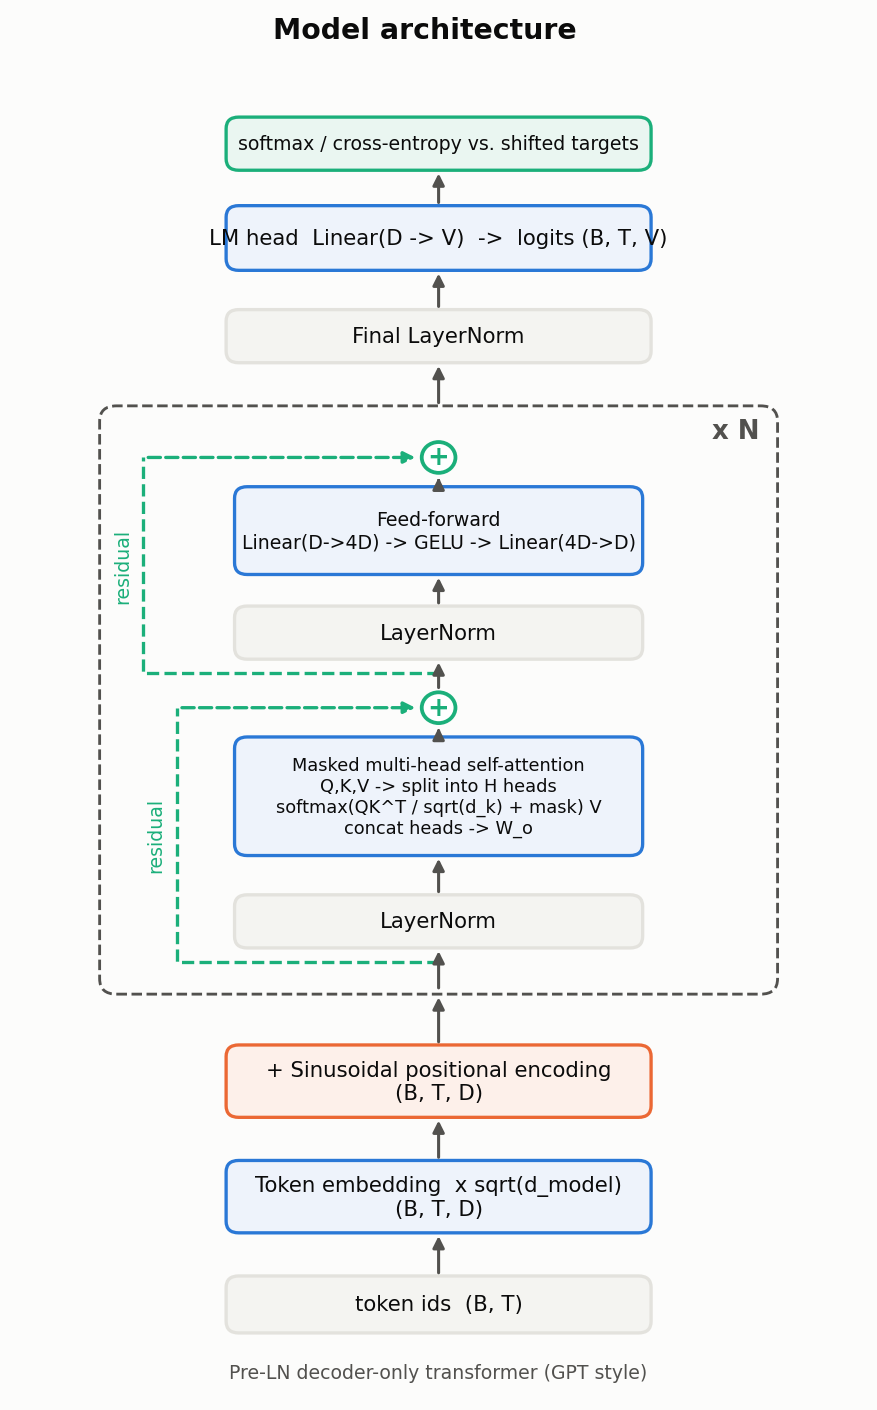

outputs/figures\fig10a_cli_inference.png


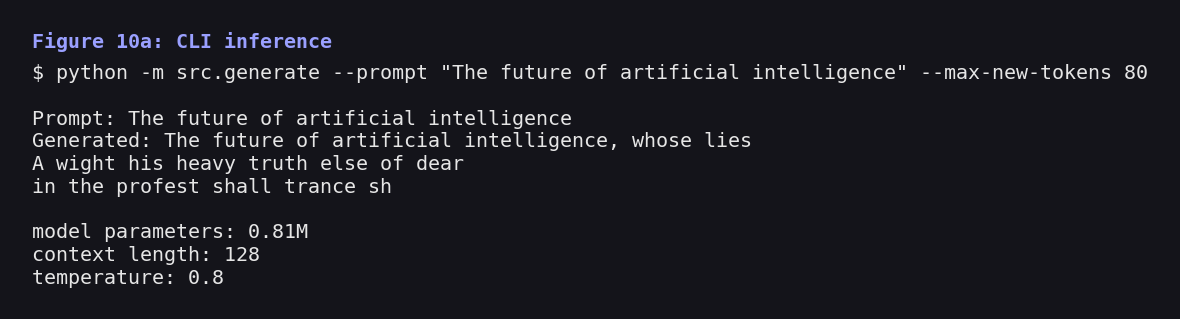

outputs/figures\fig10b_api_inference.png


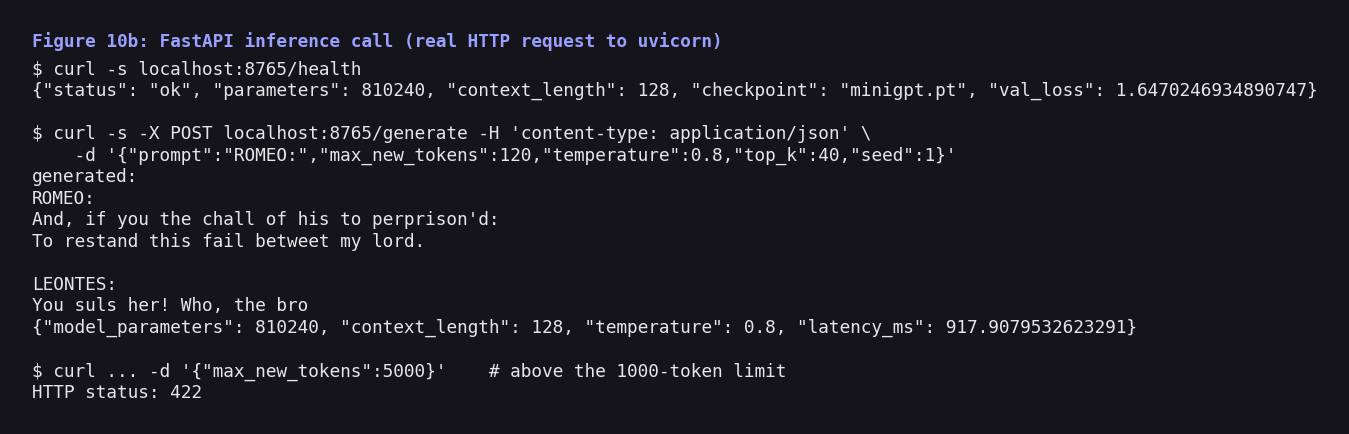

outputs/figures\fig1_hand_calculation.png


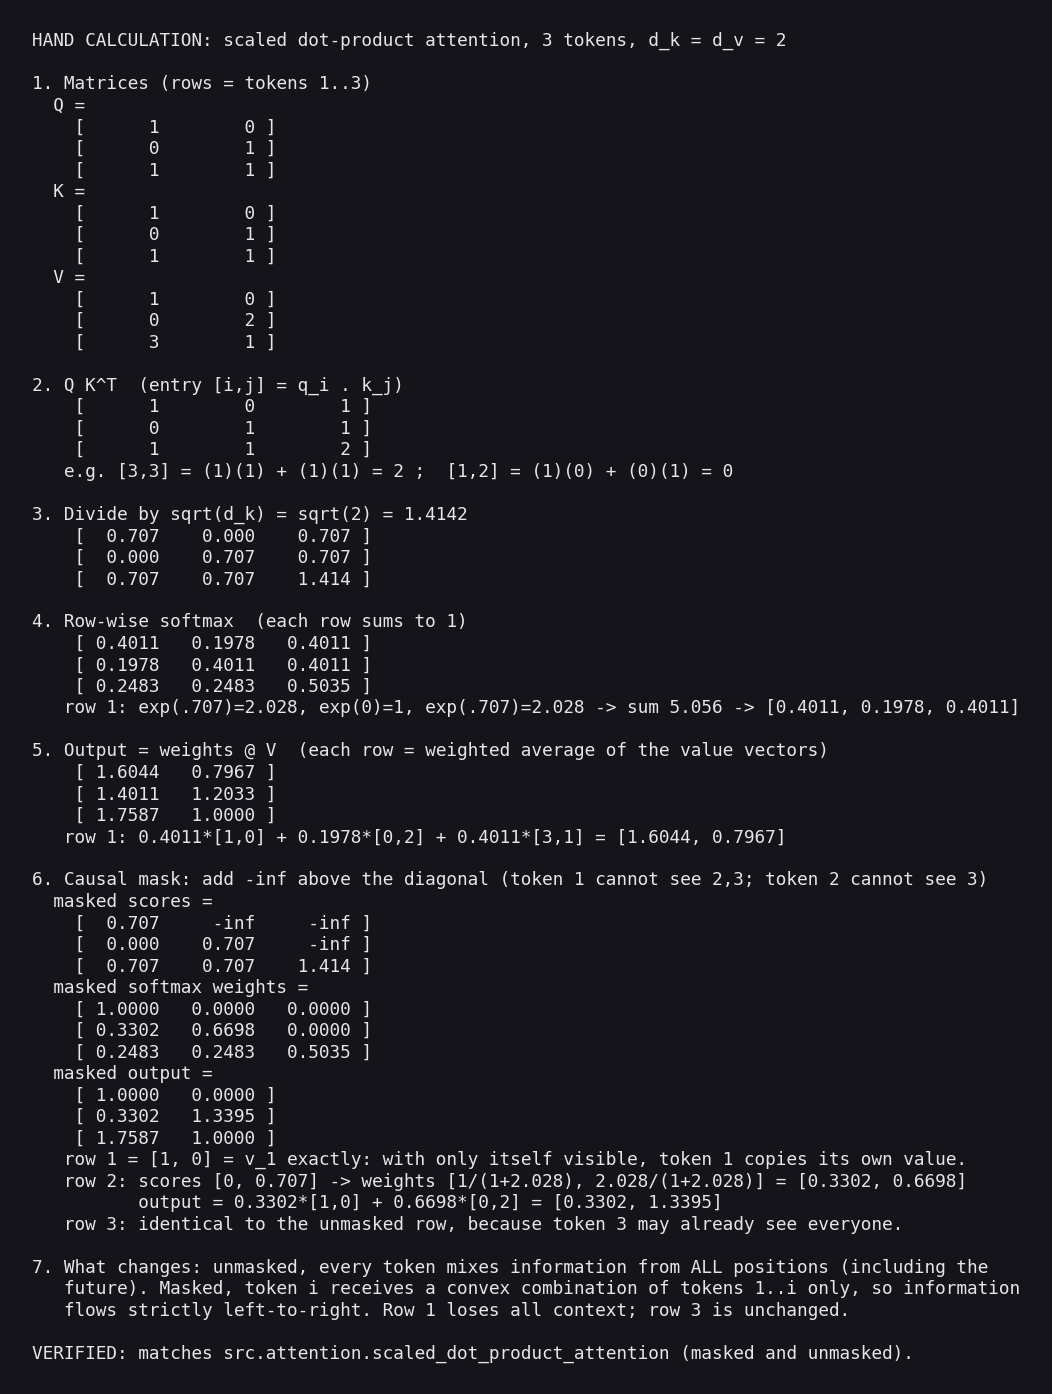

outputs/figures\fig2_causal_mask.png


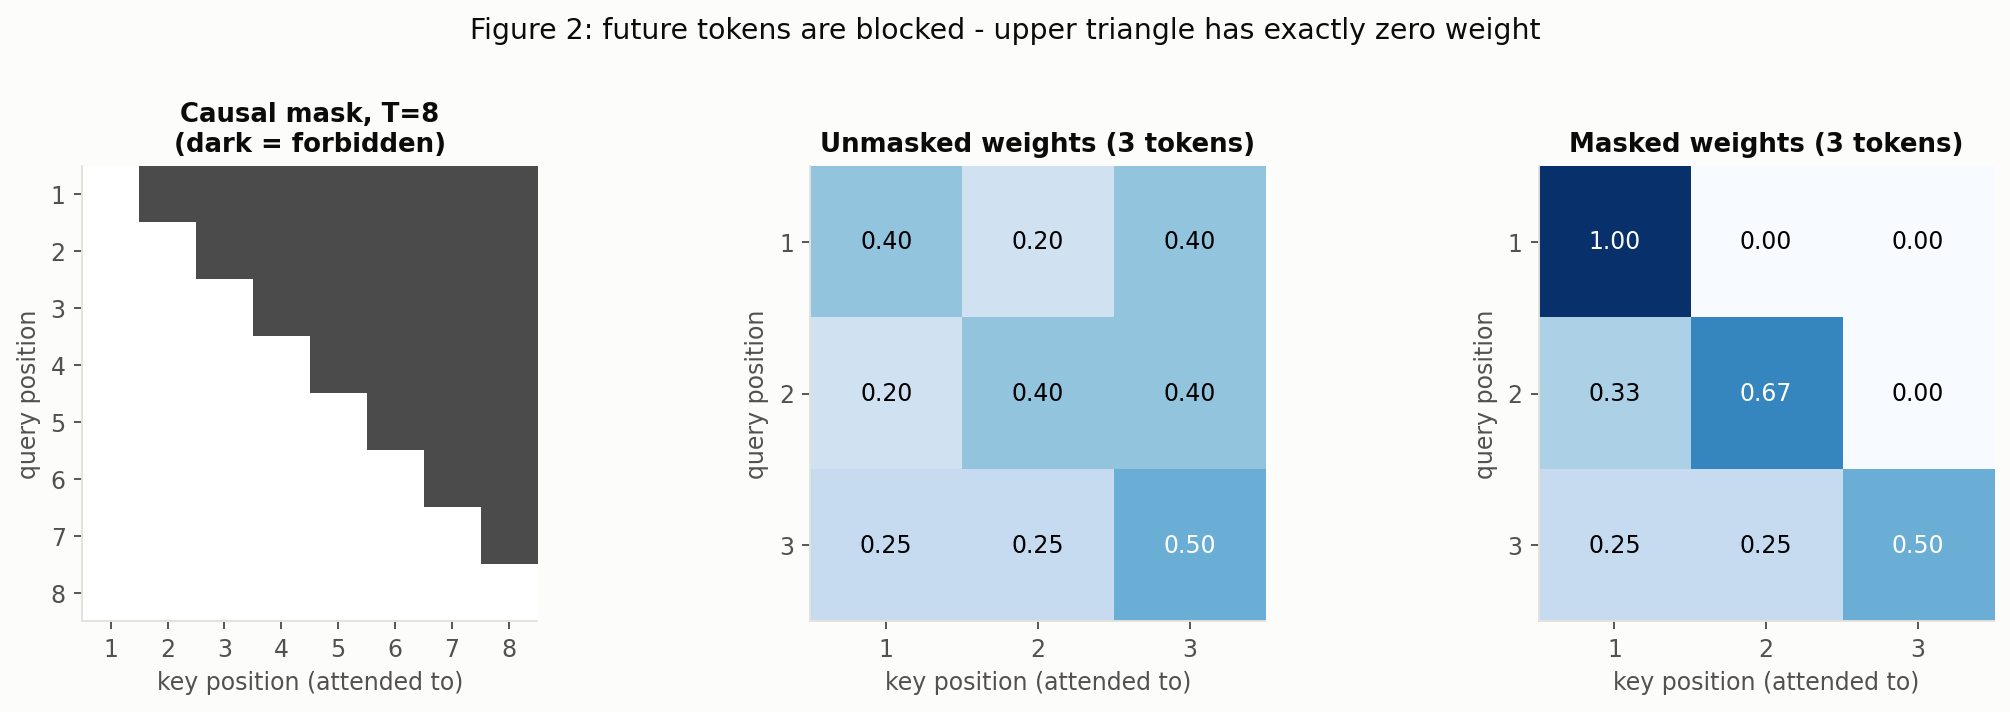

outputs/figures\fig3_multihead_shapes.png


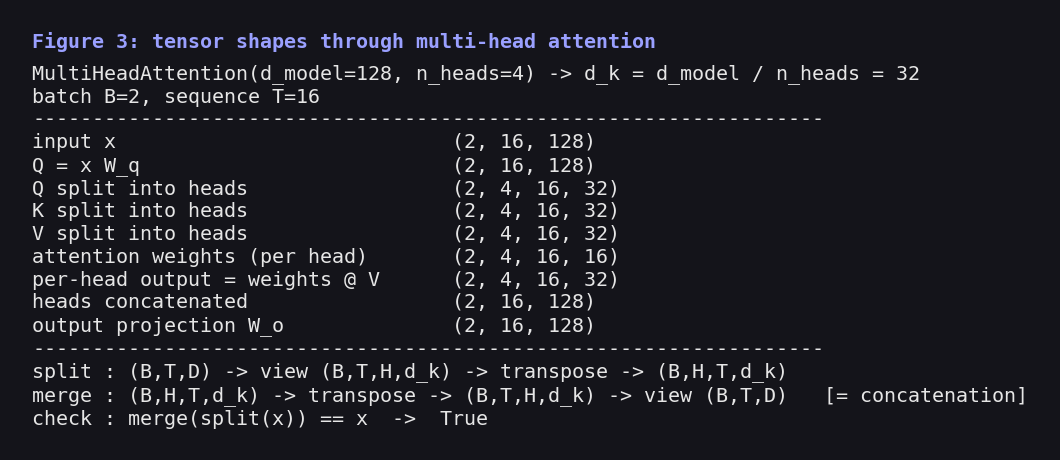

outputs/figures\fig4_positional_encoding.png


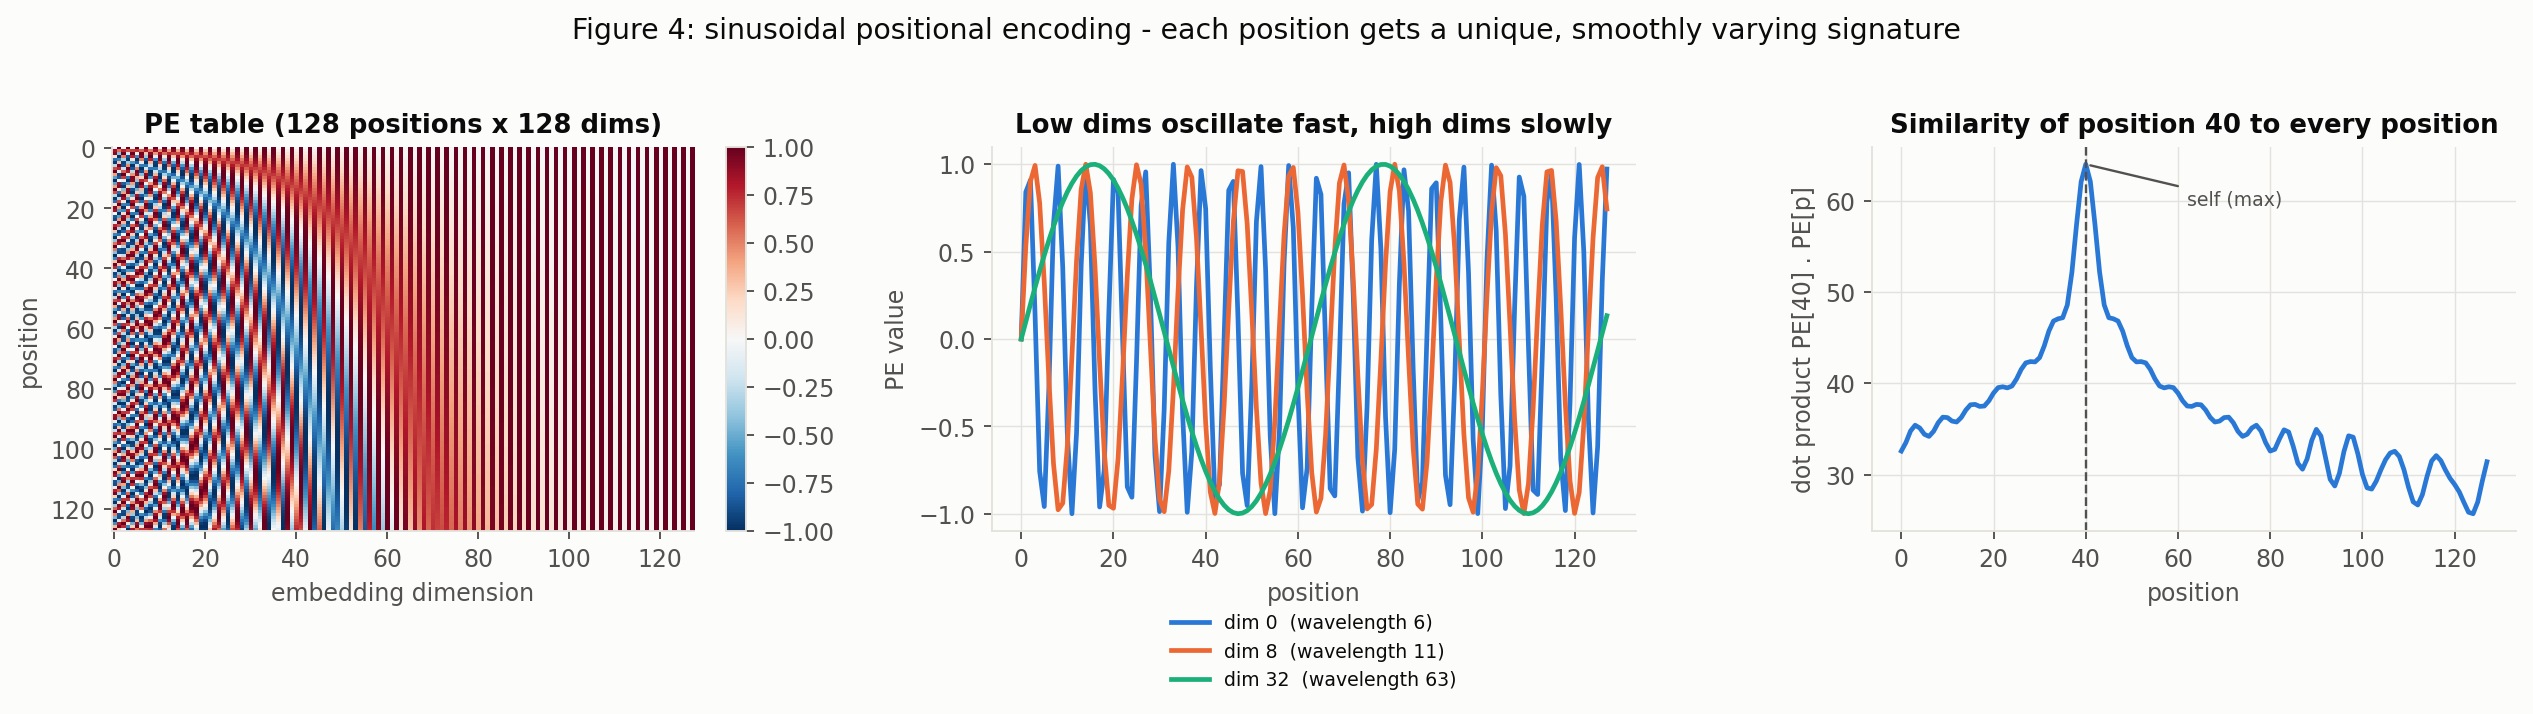

outputs/figures\fig5_model_summary.png


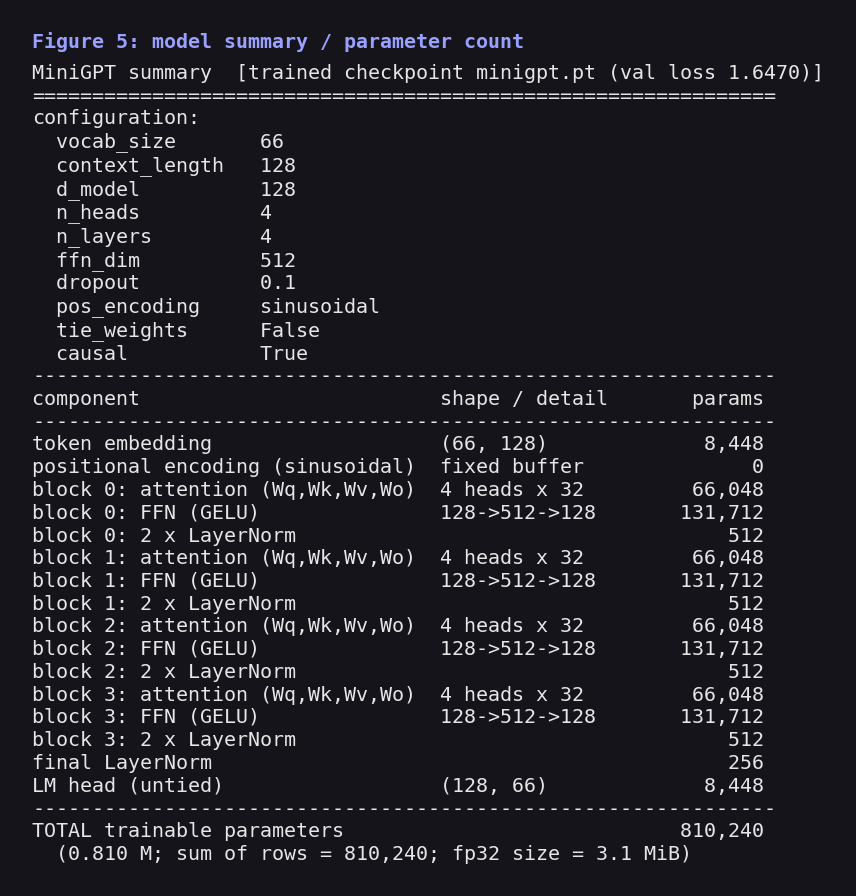

outputs/figures\fig6_loss_curves.png


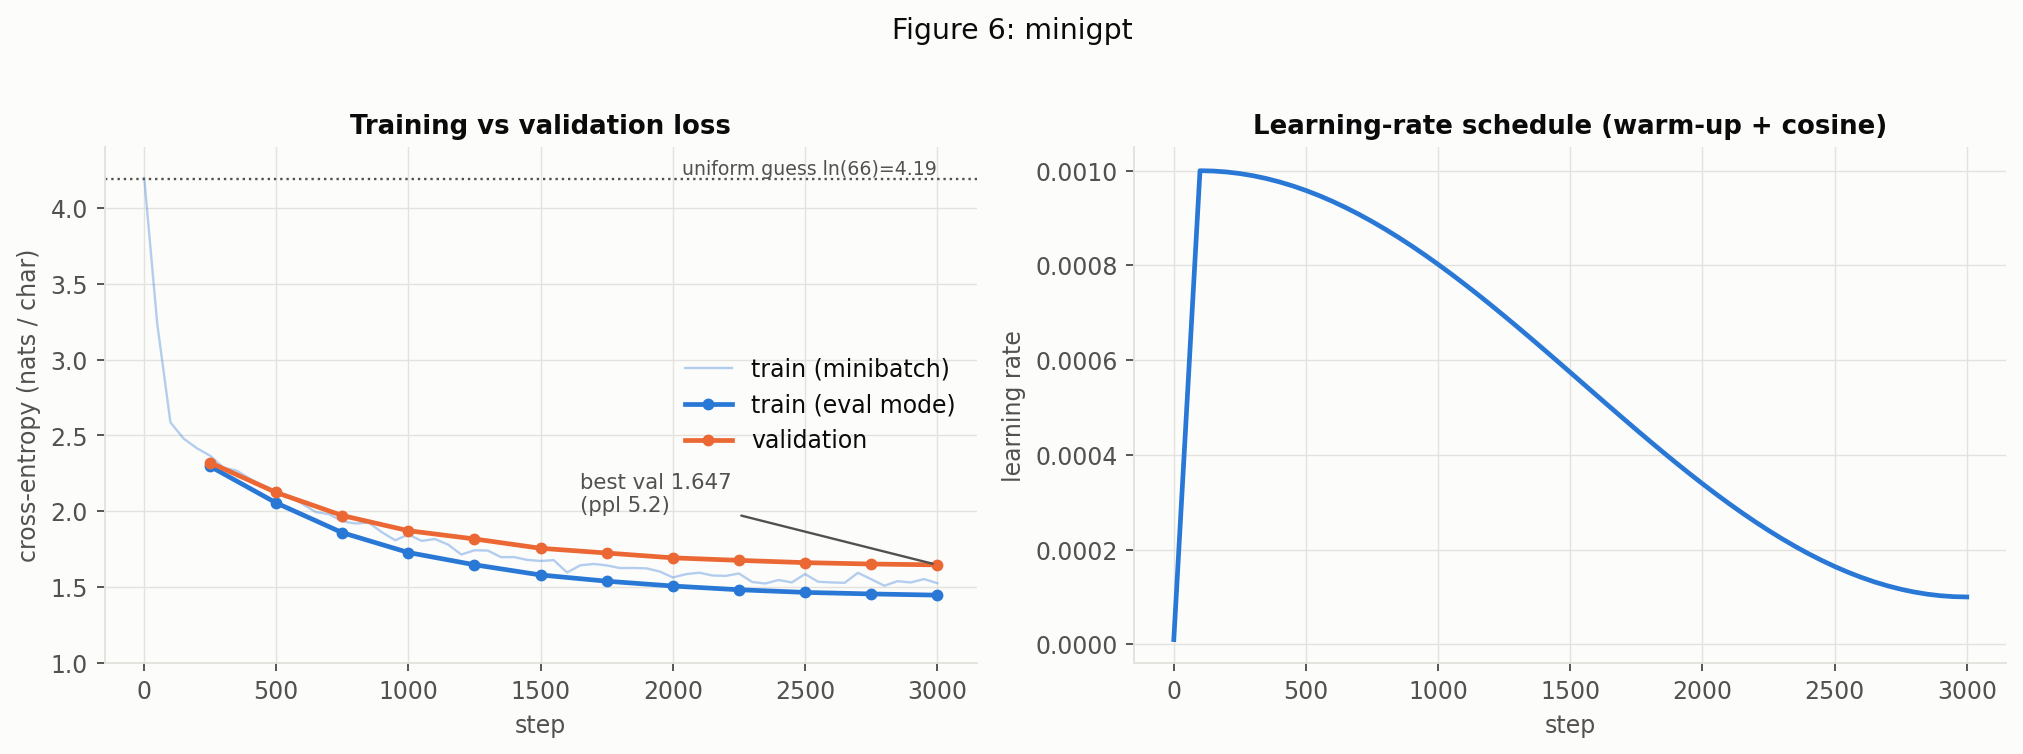

outputs/figures\fig7_attention_maps.png


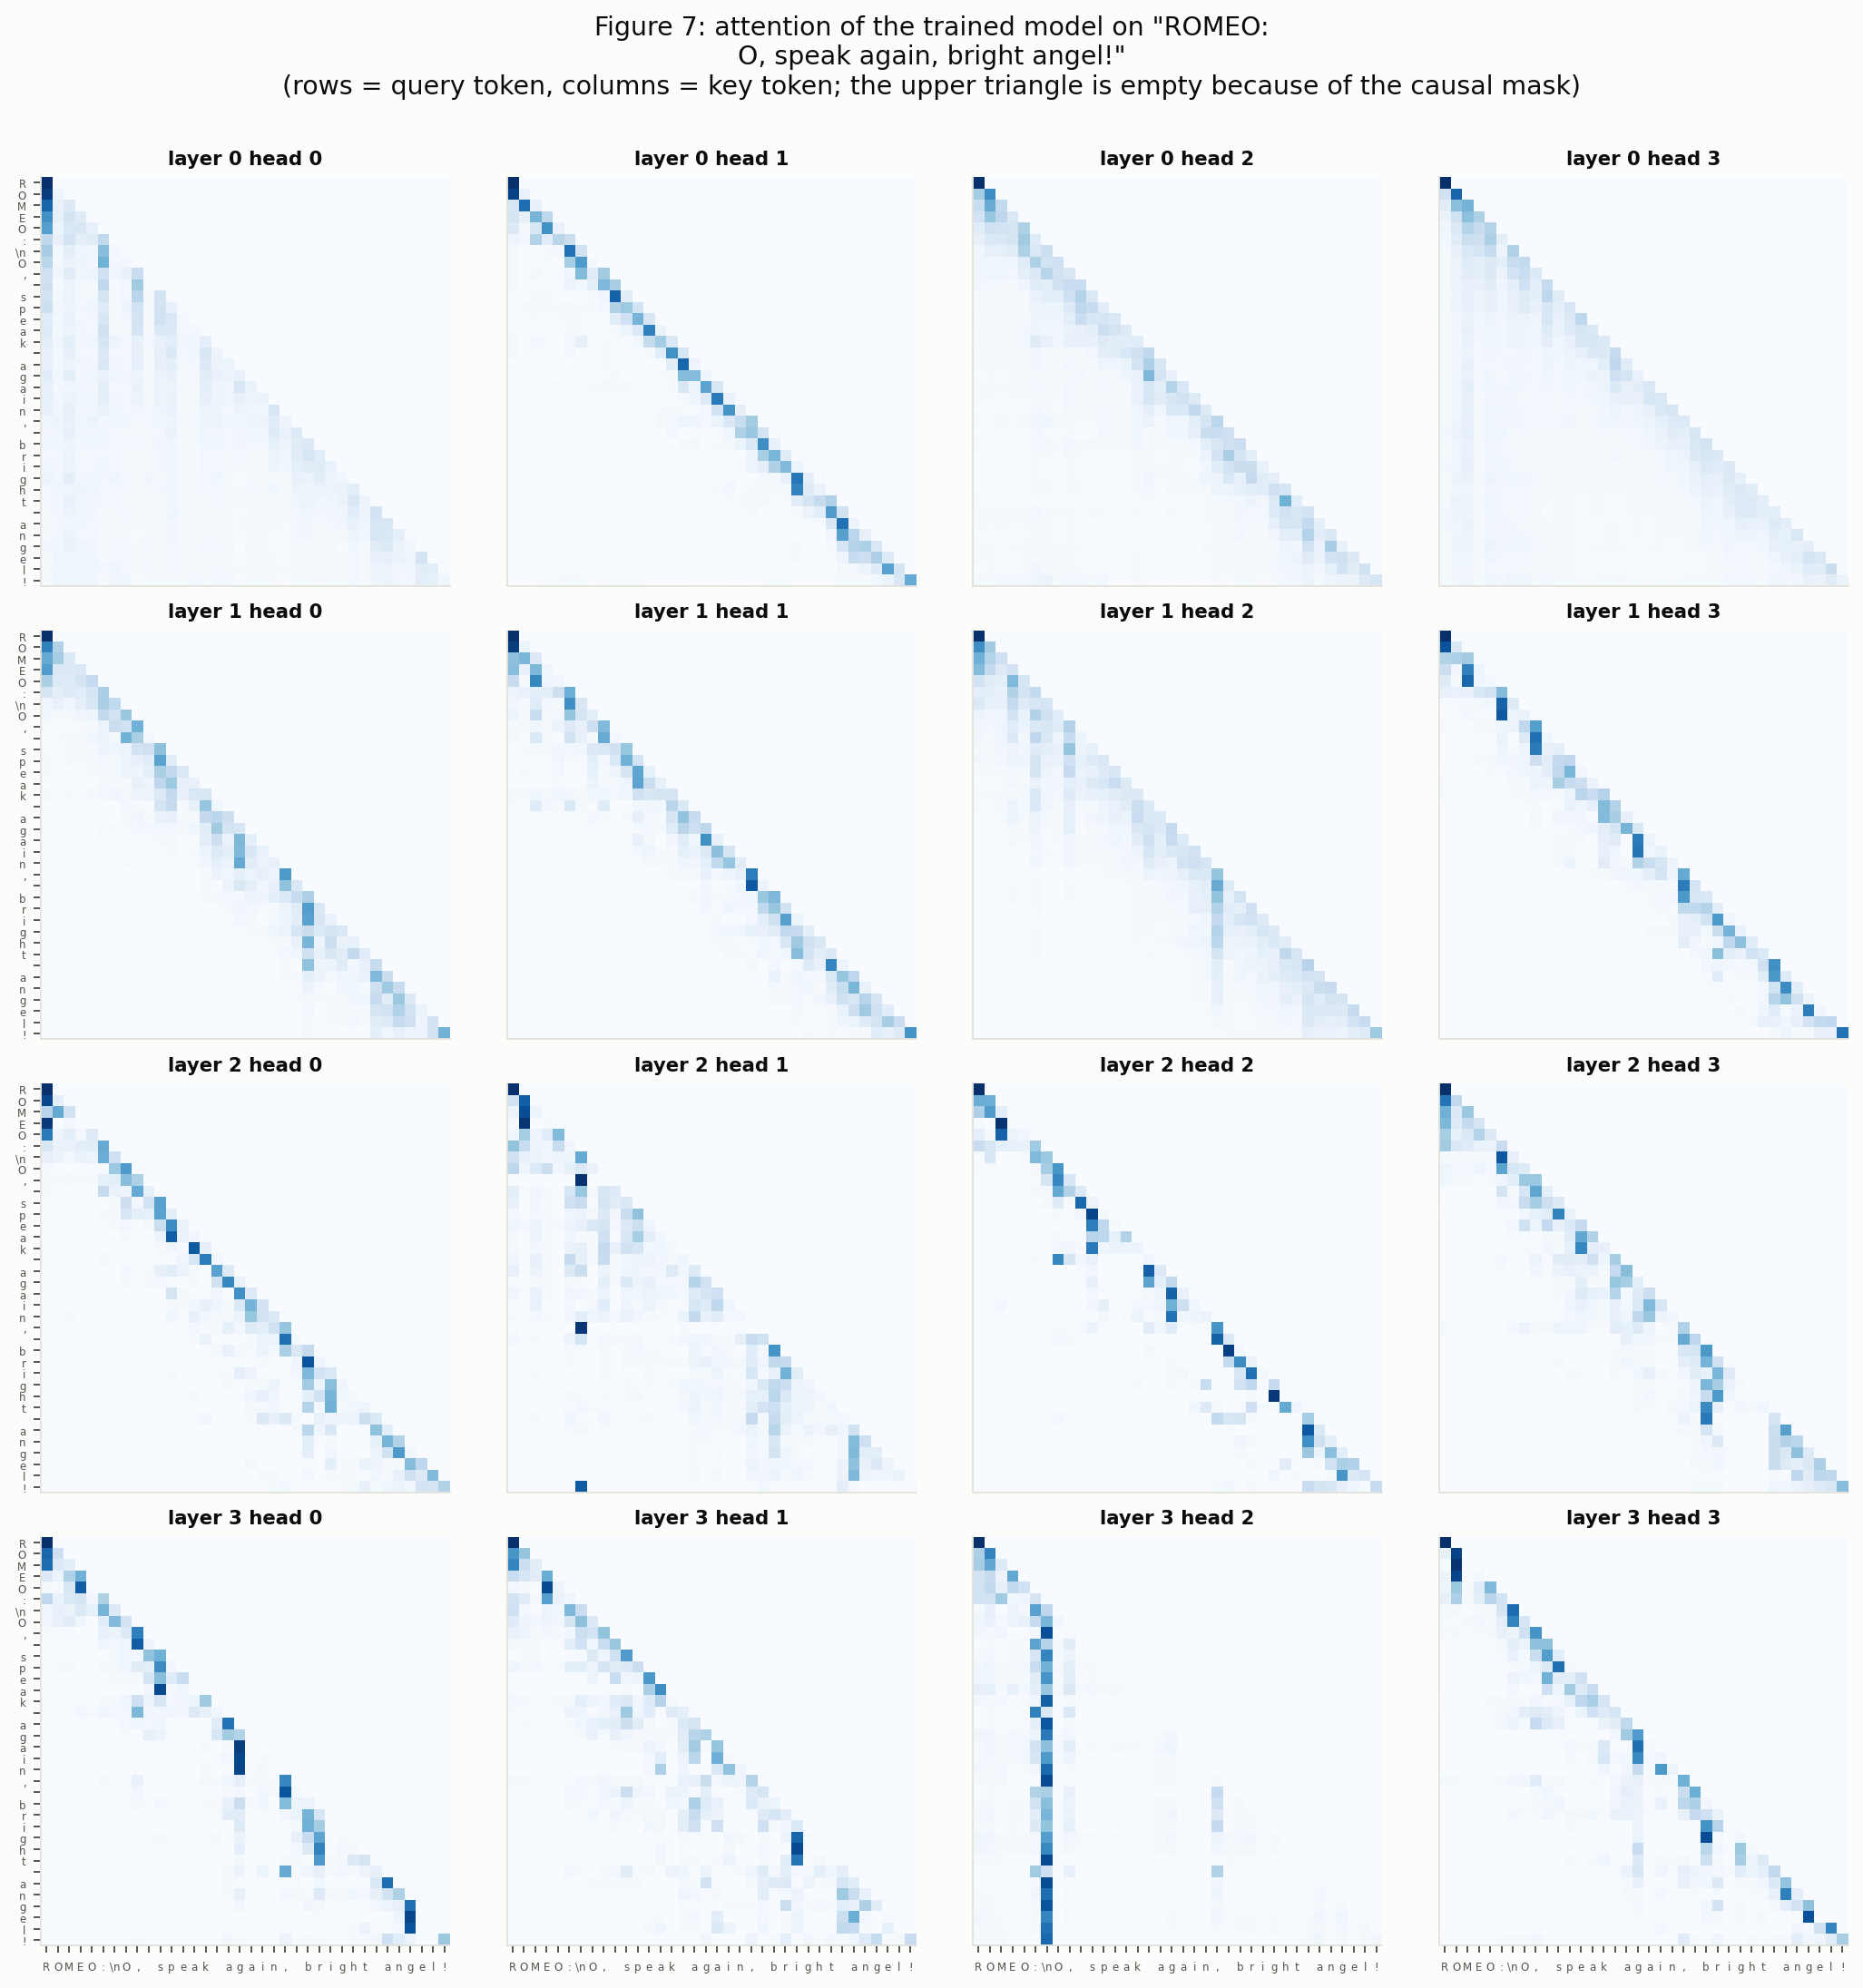

outputs/figures\fig9_ablations.png


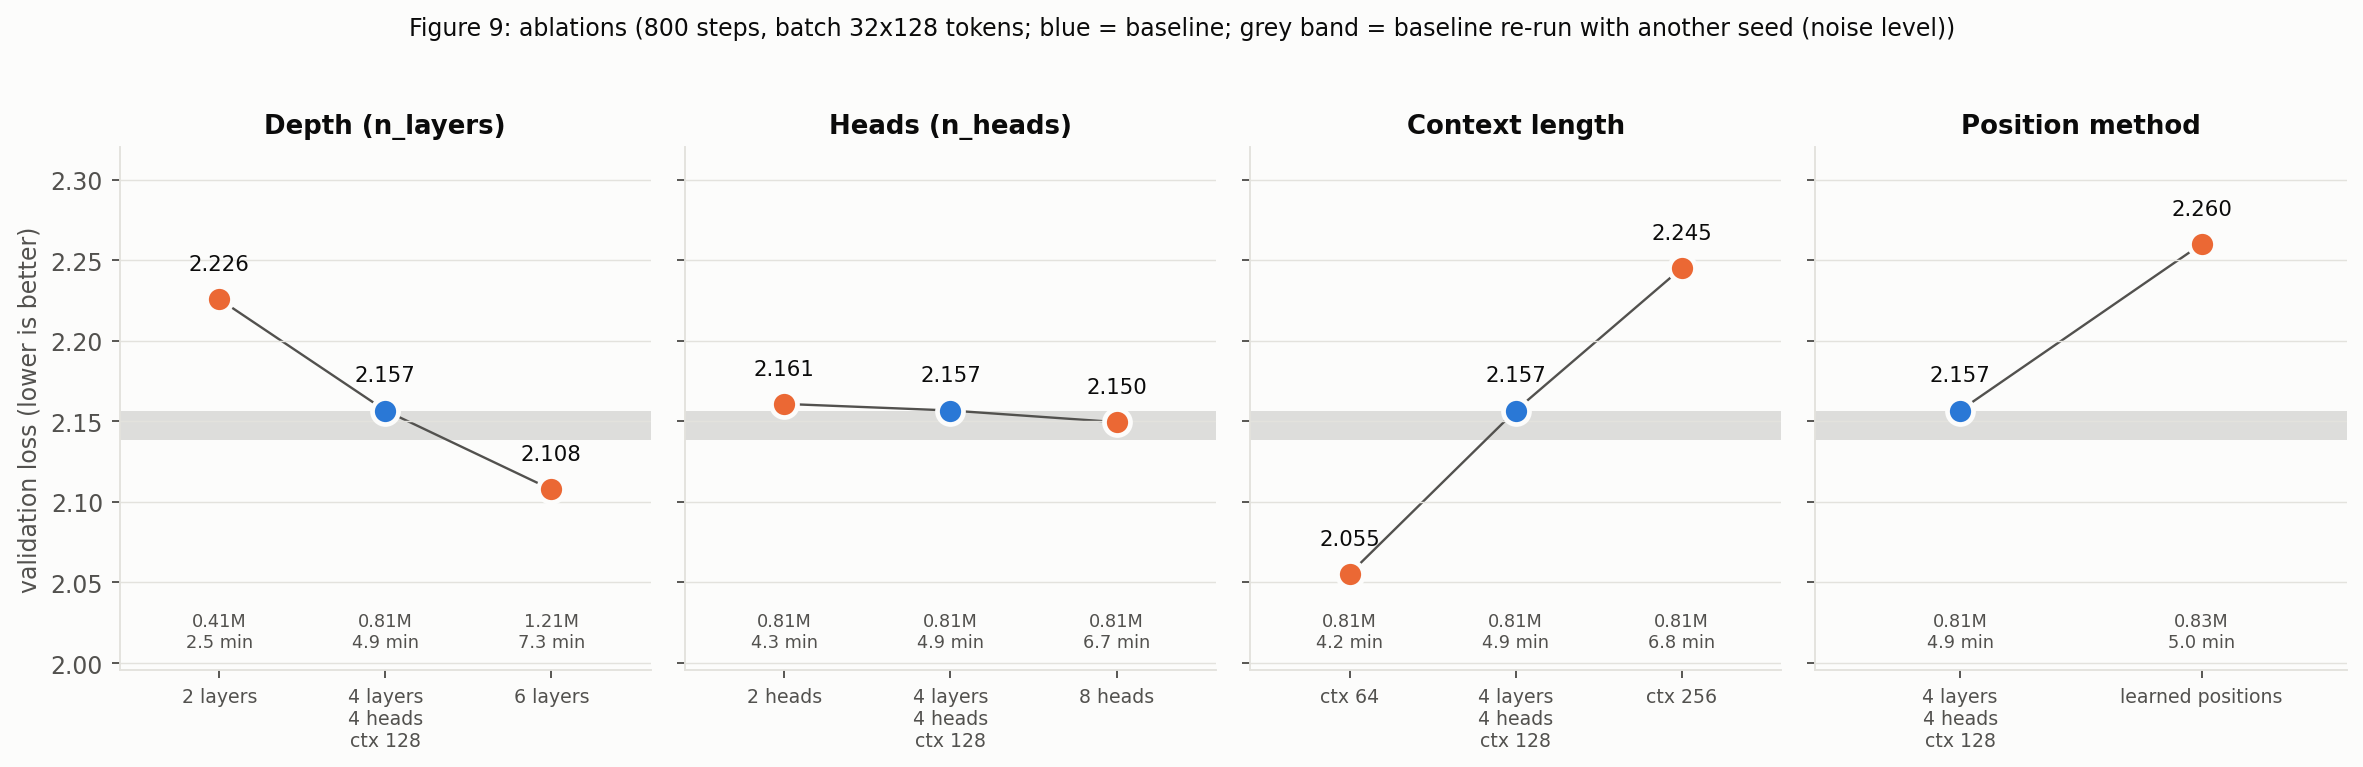

outputs/figures\fig_mlm_vs_clm_loss.png


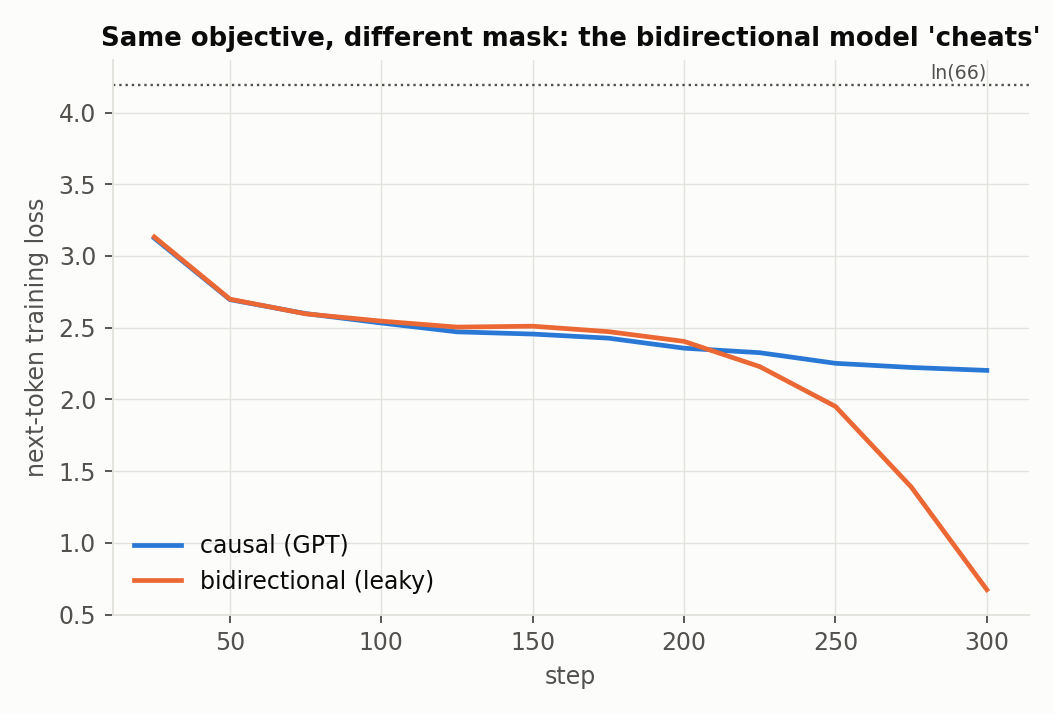

outputs/figures\fig_mlm_vs_clm_masks.png


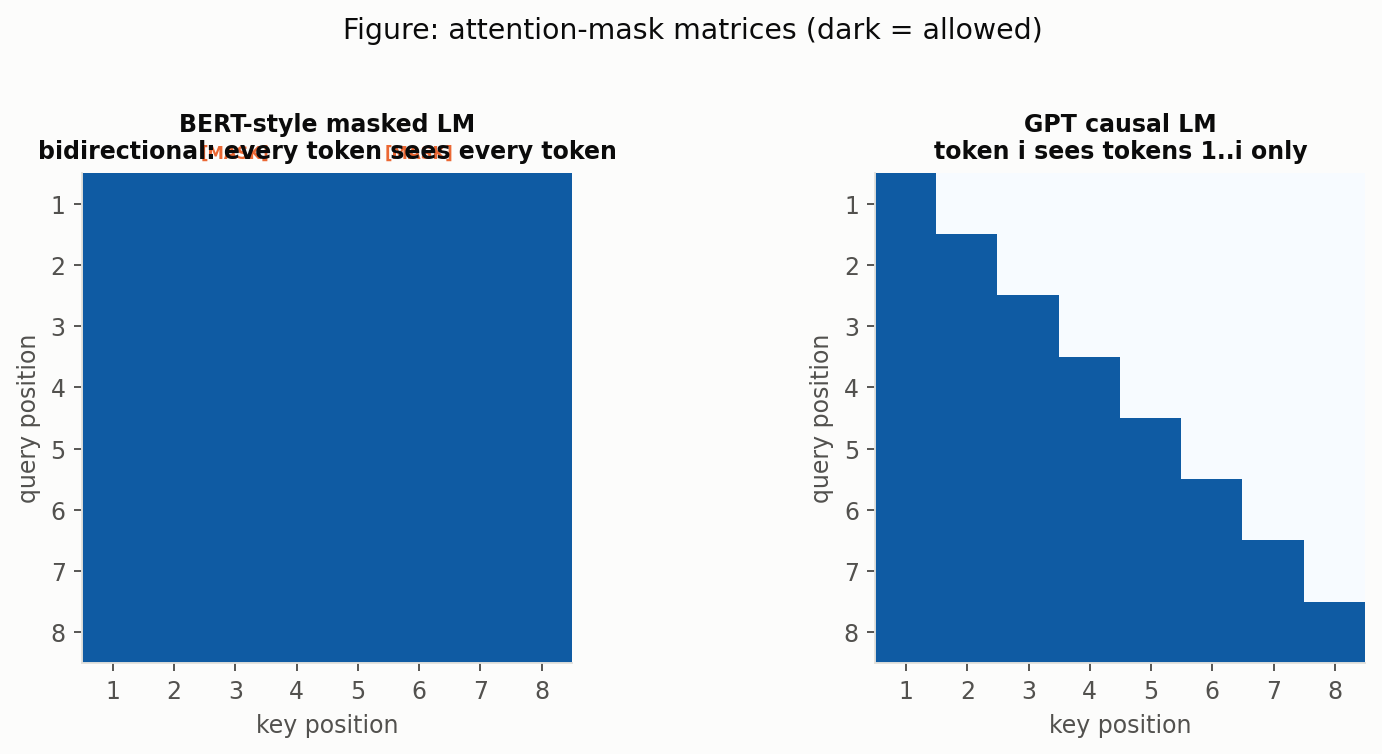

outputs/figures\fig_seq_vs_parallel.png


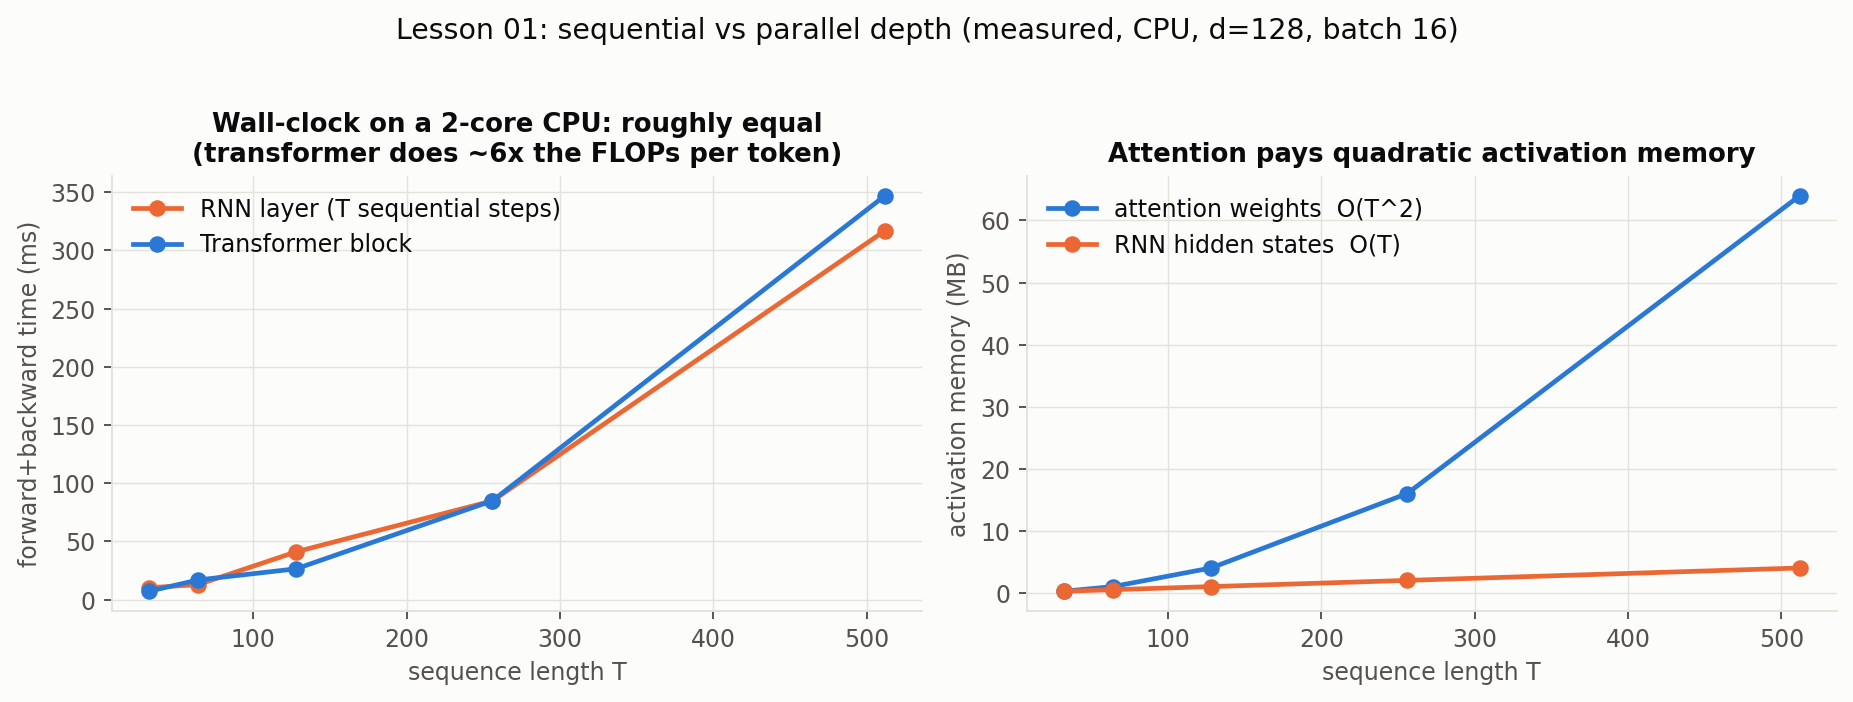

In [9]:
import glob
from IPython.display import Image, display
for f in sorted(glob.glob("outputs/figures/*.png")):
    print(f); display(Image(f))

## 9. Save outputs (checkpoint + figures + logs) to Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/minigpt_outputs
!cp -r checkpoints/minigpt.pt outputs /content/drive/MyDrive/minigpt_outputs/
print("saved to MyDrive/minigpt_outputs")